# AI101 Lab project: Retailer and HoReCa Classifier

## Description of the dataset:


The dataset that we have used for this mini-project contains the monetary spent on various items/products by the buyers which are either "Retailer" or "HoReCa". Moreover, our target column:"channel" takes the value 1 if the buyer is a "Retailer" and the value 2 if the buyer is a "HoReCa".

So, we have taken the help of a LOGISTIC REGRESSION ALGORITHM to effectively classify the buyers into two categories.

The dataset contains this exact information about 400 such buyers. It is a very clean dataset as it doesn't have missing values. We have also checked the correlation between various input features to eliminate closely-related features and hence compare the accuracy of the model before and after the removal of such features.

We found that the model which was trained on only the less-related features showed a slightly higher accuracy. We have also generated a classification report to compactly represent the performance evaluation of the base model.

## Application of our Model:

This being a simple model has limited yet some useful applications:

1. The model can help the goods owner to identify the contribution of Retailers/HoReCas in the sales and plan the prices accrodingly.
 2. A clear difference (if exists) between the numbers of the two types of buyers, can help the goods owners identify the areas of improvement for their sales.

## Installing and importing all the necessary libraries


In [1]:
%pip install numpy 
%pip install pandas 
%pip install matplotlib.pyplot
%pip install seaborn 
%pip install scikit-learn 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement matplotlib.pyplot (from versions: none)

[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for matplotlib.pyplot


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,confusion_matrix as cm_func,classification_report,recall_score,precision_score,f1_score,root_mean_squared_error,mean_absolute_error,mean_squared_error

## Defining the dataset

In [3]:
df=pd.read_csv("https://raw.githubusercontent.com/Nirbhav-Singh/Retailer-HoReCa..classification/refs/heads/main/Wholesale%20customers%20data.csv")
df.head()
#CHANNEL is the target variable here, "1":retailer and "2":HoReCa

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [4]:
print(f"shape of the dataset is (rows,columns) = {df.shape}")
print(" ")
print("information about our dataset:")
df.info()

shape of the dataset is (rows,columns) = (440, 8)
 
information about our dataset:
<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


## Analysing and pre-processing tha data:

In [5]:
print("Missing values in each column of our dataset:")
print(df.isnull().sum())


Missing values in each column of our dataset:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64


In [6]:
df = df.drop(columns=['Region'])

df.head(3)


,Channel,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,12669,9656,7561,214,2674,1338
1,2,7057,9810,9568,1762,3293,1776
2,2,6353,8808,7684,2405,3516,7844


In [7]:
df.head(2)

,Channel,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,12669,9656,7561,214,2674,1338
1,2,7057,9810,9568,1762,3293,1776


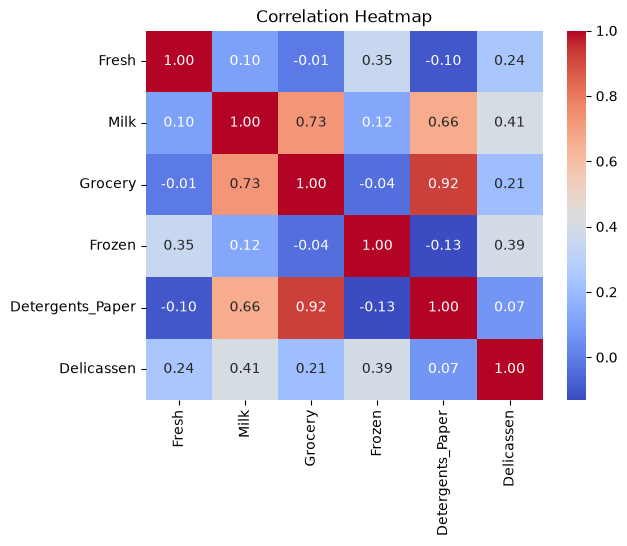

In [8]:
# now we will pickout the features which have a high correlation
features = df[["Fresh","Milk","Grocery","Frozen","Detergents_Paper","Delicassen"]]
features.head(2)
correlations = features.corr(numeric_only=True)


sns.heatmap(correlations, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()


 #### Now we can see that "detergents" and "grocery" are strongly correlated,so we will train two models separately to see the difference after removing a feature.

## Training the base logistic regression model:

In [9]:
x = features # these are the independent feature columns
y = df["Channel"]# this is our target Variable.
xtrain,xtest,ytrain,ytest=train_test_split(
    x,y,
    test_size=0.15,# keeping 15% data(60 rows) for testing
    random_state=40,
    stratify=y# to ensure that the training set and testing set contain the target classes in equal proportion
)
print("train_test_split done!")

train_test_split done!


In [10]:
# scaling the features and fitting the model on them:
tool = StandardScaler()
xtrain_scaled = tool.fit_transform(xtrain)

# applying the scaling on test data as well:
xtest_scaled = tool.transform(xtest)
print("We have now completed the feature scaling process!")

We have now completed the feature scaling process!


In [11]:
#fitting and training the model
Model1 = LogisticRegression(max_iter=80)#providing enough number of iterations so that model can learn the weights successfully
Model1.fit(x,y)
print("Model training complete!")

Model training complete!


## Making predictions on the test set:

In [12]:
# assinging labels to target variable using a dictionary.
class_names = {
    1: "Retailer(1)",
    2: "HoReCa(2)"
}
# predicting using a single datapoint from the test set:
new_customer = xtest.iloc[[3]]
prediction = Model1.predict(new_customer)

print(f"predicted: {class_names[prediction[0]]}, actual:({ytest.iloc[3]})")

predicted: Retailer(1), actual:(1)


In [13]:
#Testing on the whole test set at once:
predictions = Model1.predict(xtest)

#Measuring performance
acc = accuracy_score(ytest,predictions)
print(f"accuracy(in percentage) of the model is:{round(acc*100,3)}%")
cm = cm_func(ytest,predictions)
print(" ")
print(f"confusion matrix is as follows:")
print(cm)

accuracy(in percentage) of the model is:92.424%
 
confusion matrix is as follows:
[[42  3]
 [ 2 19]]
